# Lecture 16 notebook: a trend rule on the tape

This notebook replays Lecture 16 on the tape of Lecture 12 and the dollar bars of Lecture 13. Every figure and number of the lecture comes from a
script in `scripts/`, next to this notebook; each runs in a fresh process, so that memory is freed after every step.

| § | Content | Lecture |
|---|---|---|
| 0 | Settings | |
| 1 | Three clocks, and the instrument: funding, basis, the pure premium | §1 |
| 2 | The rule on BTCUSDT: speeds and candle sizes | §2 |
| 3 | The information clock: trend measures from dollar bars | §3 |
| 4 | Risk: its two parts, and sizing by forecast risk | §4 |
| 5 | The execution clock: the patient entry | §5 |
| 6 | Holding: funding by leg, the premium, perpetual or spot | §6 |
| 7 | The rule built up, its legs and capacity | §7 |
| 8 | The grid, schematic | §8 |
| 9 | A test of your own | §9.2 |

**Before you start.** Lecture 12's notebook must have built the tape, and Lecture 13's notebook the dollar bars, for October 2021 to September 2026.
§1 downloads Binance's premium index and spot daily candles (small files). Results go to `data/interim/l16`; figures are saved in `figures/` as
`nb_*`, so the lecture's own figures are never overwritten. Most steps take a few minutes; the whole notebook about an hour.

## 0. Settings

In [1]:
import json, os, subprocess, sys, time
from pathlib import Path
import numpy as np, polars as pl, psutil
from IPython.display import Image, Markdown, display

HERE = Path.cwd()
SCRIPTS, FIG = HERE / "scripts", HERE / "figures"
sys.path[:0] = [str(SCRIPTS), str(HERE.parent / "13-bars-not-cut-by-time" / "scripts"), str(HERE.parent / "12-tick-data-the-tape"), str(HERE.parents[1])]
import tape
OUT = tape.ROOT / "interim" / "l16"

pl.Config.set_tbl_rows(40); pl.Config.set_fmt_str_lengths(80); pl.Config.set_tbl_width_chars(200)
print("data folder:", "the folder in the environment variable TAPE_ROOT" if os.environ.get("TAPE_ROOT") else "data/ at the top of the repository")
print(f"free memory: {psutil.virtual_memory().available / 1e9:.1f} GB of {psutil.virtual_memory().total / 1e9:.1f} GB")


def run(script, *args, show=False):
    """Run a script of scripts/ in a fresh process; figures to figures/ as nb_*, results to data/interim/l16."""
    t0 = time.time()
    env = {**os.environ, "TAPE_ROOT": str(tape.ROOT), "L16_PREFIX": "nb_", "PYTHONIOENCODING": "utf-8"}
    p = subprocess.run([sys.executable, "-I", str(SCRIPTS / script), *args], capture_output=True, text=True, encoding="utf-8", env=env)
    if p.returncode:
        print(p.stdout[-2000:], p.stderr[-4000:]); raise RuntimeError(f"{script} failed")
    print(f"{script}: {time.time() - t0:.0f} s")
    if show: print(p.stdout)


def result(name):
    return json.loads((OUT / name).read_text(encoding="utf-8"))


def pictures(*names):
    for nm in names:
        f = FIG / f"nb_{nm}.png"
        display(Image(filename=str(f))) if f.exists() else print("not drawn yet:", f.name)

data folder: the folder in the environment variable TAPE_ROOT
free memory: 2.1 GB of 16.9 GB


## 1. Three clocks, and the instrument

Lecture §1: the decision clock and the dollar-bar clock on one day, and how an hourly rule reads a value from dollar bars (figures 16_01, 16_02);
the premium index against the funding actually paid; and the pure premium, long spot and short the perpetual, with its exact formula.

l16_downloads.py: 1 s
futures/um/monthly/premiumIndexKlines/BTCUSDT/1h: 61 files (0 new)
futures/um/monthly/premiumIndexKlines/BTCUSDT/8h: 61 files (0 new)
spot/monthly/klines/BTCUSDT/1d: 60 files (0 new)



l16_s1_chart.py: 4 s


l16_s1b_chart.py: 5 s


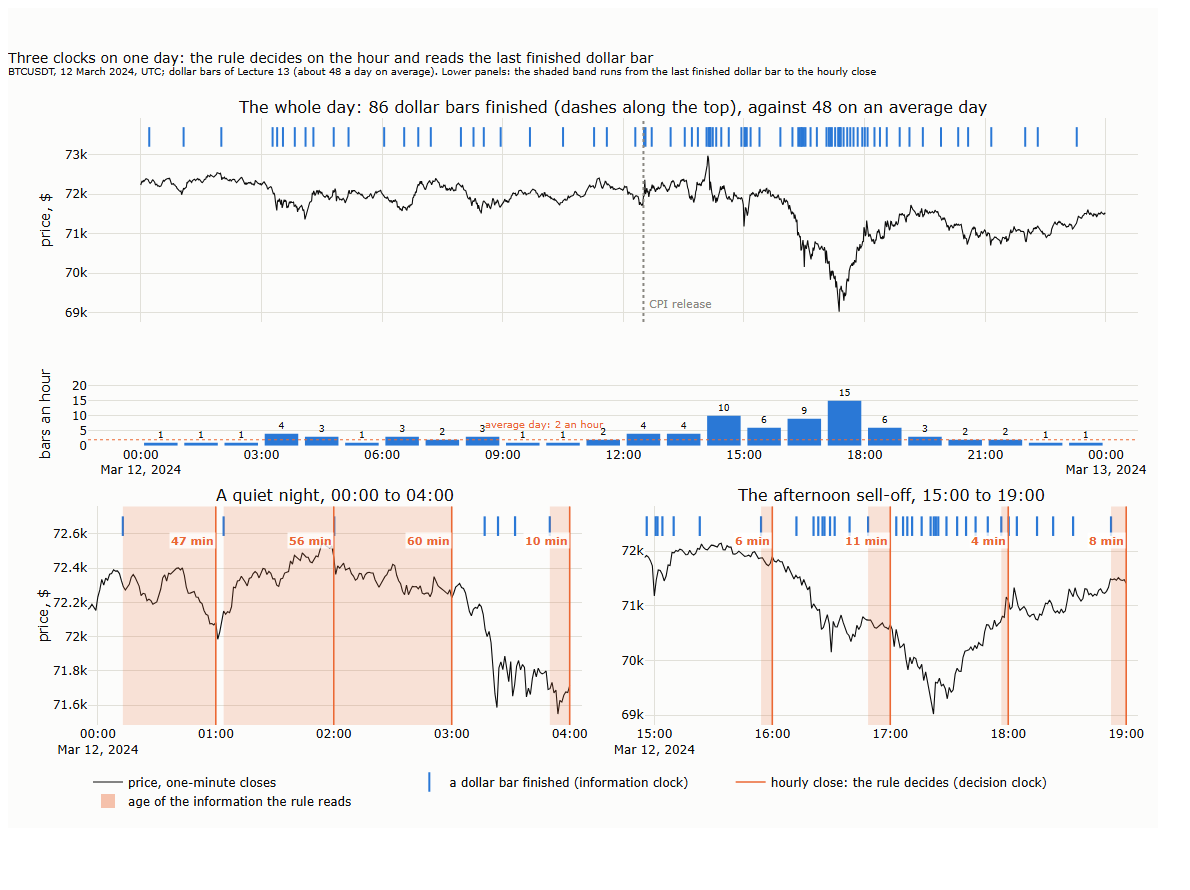

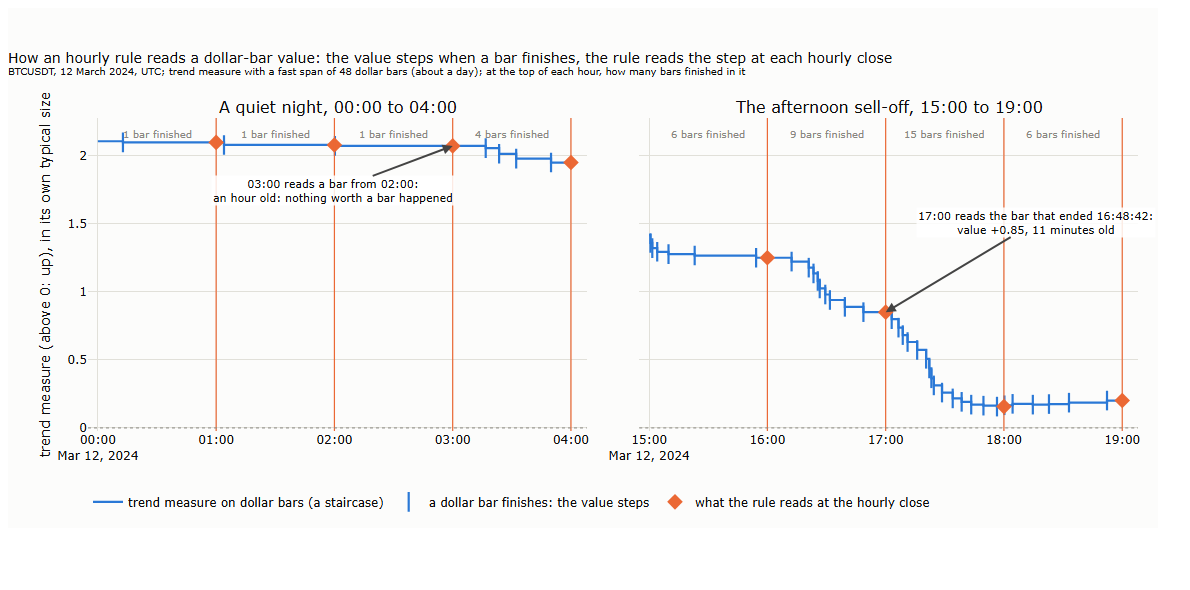

l16_premium_check.py: 2 s
8h candle open hours: [{'t': 0, 'count': 1853}, {'t': 8, 'count': 1853}, {'t': 16, 'count': 1853}]
from the 8-hour candle: correlation with actual funding 0.638, median absolute gap 0.330 bp, exact to 0.1 bp: 31.5%
from the hourly candles: correlation with actual funding 0.901, median absolute gap 0.151 bp, exact to 0.1 bp: 42.0%
intervals matched: 5470 2021-09-30 16:00:00 2026-09-30 16:00:00
weighted towards the end: correlation 0.884, median absolute gap 0.153 bp, exact to 0.1 bp: 42.3%



l16_carry.py: 1 s


**Long spot, short perpetual:** total 43.5% (7.5% a year); risk-free 3.9% a year; excess 3.6% a year; basis -1.7 bp at the start, -5.6 bp at the end

year,funding_pct,basis_change_pct,bill_pct,excess_pct
i64,f64,f64,f64,f64
2021,5.05,0.02,0.01,5.05
2022,4.16,-0.02,2.0,2.14
2023,7.82,-0.12,5.06,2.64
2024,12.01,0.12,4.98,7.14
2025,5.14,-0.0,4.07,1.07
2026,2.21,0.02,2.75,-0.52


In [2]:
run("l16_downloads.py", show=True); run("l16_s1_chart.py"); run("l16_s1b_chart.py")
pictures("16_01_three_clocks", "16_02_reading_another_clock")
run("l16_premium_check.py", show=True); run("l16_carry.py")
c = result("l16_carry.json")
display(Markdown(f"**Long spot, short perpetual:** total {c['total_return_compounded']:.1%} ({c['total_return_per_year_compounded']:.1%} a year); "
                 f"risk-free {c['riskfree_per_year_compounded']:.1%} a year; excess {c['excess_per_year_compounded']:.1%} a year; basis {c['basis_start_bp']} bp at the start, {c['basis_end_bp']} bp at the end"))
pl.DataFrame(c["by_year"])

## 2. The rule on BTCUSDT

Lecture §2: the plain rule at fast spans from 3 hours to 3 weeks (figure 16_03), the same rule on candles of 5 minutes to a day (figure 16_04),
and the blend of the plateau speeds, 1, 2 and 3 days, used in every later section.

l16_trend_bars.py: 4 s


l16_s2.py: 5 s


l16_blend.py: 1 s


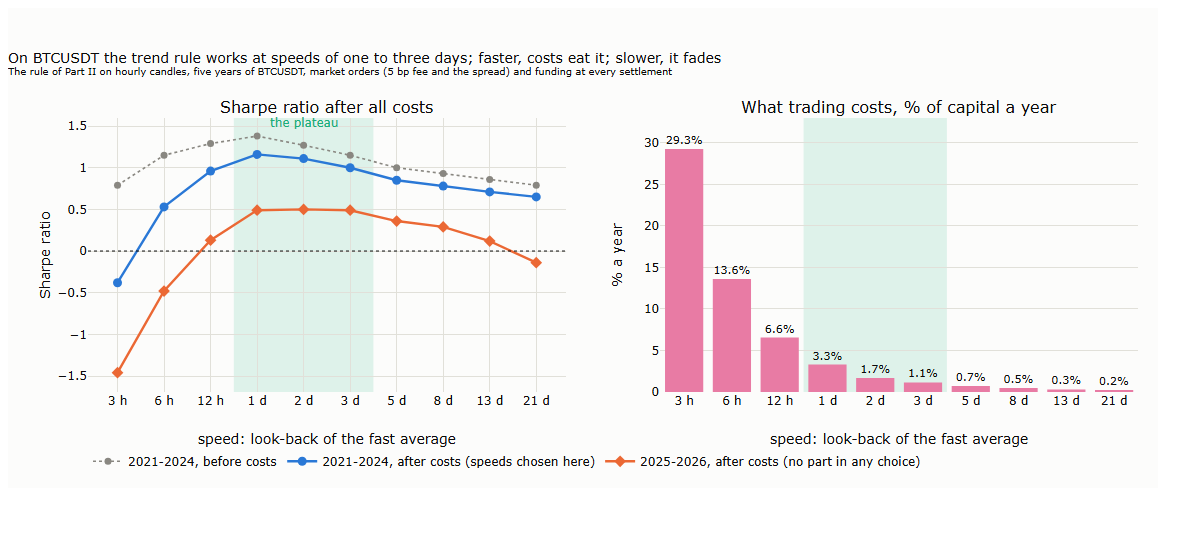

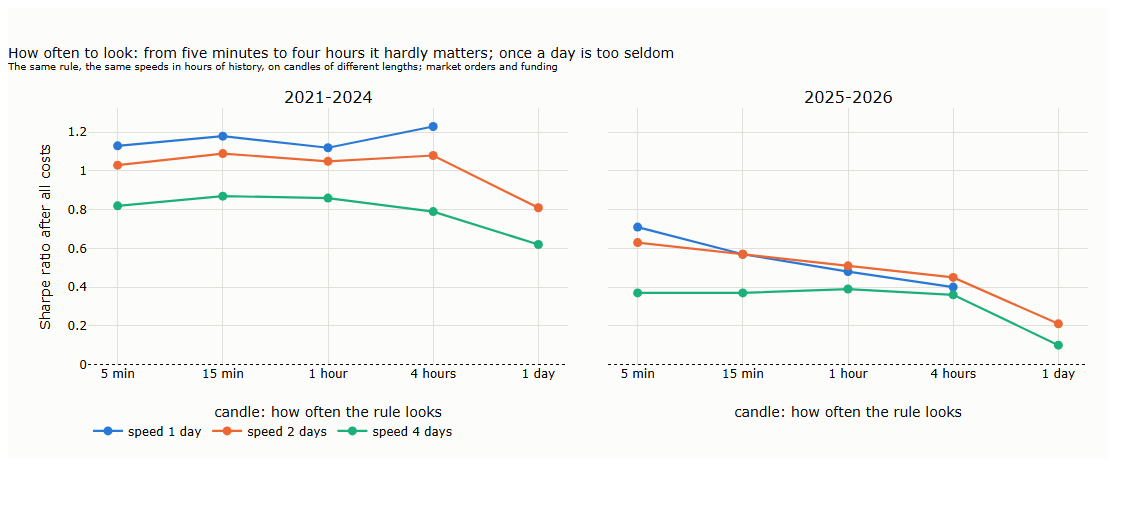

sample,sharpe,ret,vol,maxdd,cost,funding,turnover
str,f64,f64,f64,f64,f64,f64,f64
"""2021-2024""",1.14,0.2219,0.1941,-0.1549,0.02,0.0141,39.7
"""2025-2026""",0.52,0.0886,0.1695,-0.1704,0.0226,0.0027,44.9


In [3]:
run("l16_trend_bars.py"); run("l16_s2.py"); run("l16_blend.py")
pictures("16_03_speed_curve", "16_04_candle_size")
b = result("l16_blend.json")
pl.DataFrame([{"sample": k, **{x: v[x] for x in ("sharpe", "ret", "vol", "maxdd", "cost", "funding", "turnover")}} for k, v in b.items()])

## 3. The information clock

Lecture §3: the hourly rule reading its trend measure from hourly closes (A), from dollar bars with an average counted in bars (B), or from dollar
bars with an average fading by time (C); figure 16_05. Then the same check with a breakout rule.

l16_plugin.py: 3 s


l16_s3_chart.py: 3 s


l16_breakout.py: 3 s


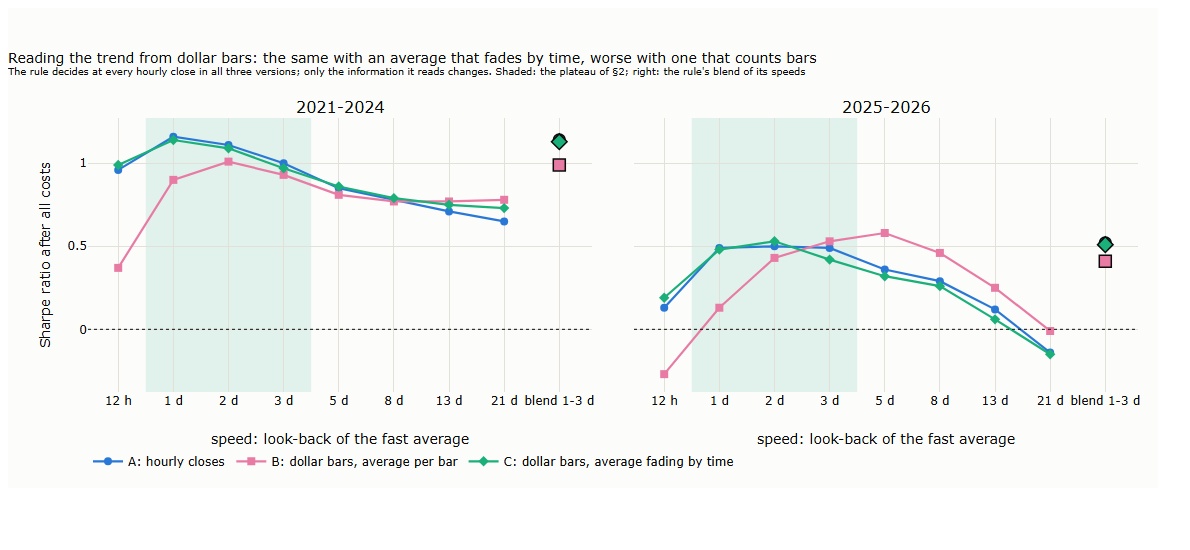

speed,version,Sharpe 2021-2024,Sharpe 2025-2026,costs,corr with A
str,str,f64,f64,f64,f64
"""0.5 d""","""A time bars""",0.96,0.13,0.0656,1.0
"""0.5 d""","""B dollar bars, per bar""",0.37,-0.27,0.0724,0.839
"""0.5 d""","""C dollar bars, decay by time""",0.99,0.19,0.047,0.991
"""1 d""","""A time bars""",1.16,0.49,0.0331,1.0
"""1 d""","""B dollar bars, per bar""",0.9,0.13,0.0365,0.868
"""1 d""","""C dollar bars, decay by time""",1.14,0.48,0.0242,0.993
"""2 d""","""A time bars""",1.11,0.5,0.0169,1.0
"""2 d""","""B dollar bars, per bar""",1.01,0.43,0.0179,0.904
"""2 d""","""C dollar bars, decay by time""",1.09,0.53,0.0125,0.995


channel,version,Sharpe 2021-2024,Sharpe 2025-2026
str,str,f64,f64
"""1 d""","""A hourly closes""",-0.41,-0.44
"""1 d""","""B dollar bars""",-0.59,-0.49
"""2 d""","""A hourly closes""",0.06,-0.45
"""2 d""","""B dollar bars""",0.33,0.22
"""3 d""","""A hourly closes""",0.73,-0.01
"""3 d""","""B dollar bars""",0.18,-0.04
"""5 d""","""A hourly closes""",0.86,-0.21
"""5 d""","""B dollar bars""",0.41,0.12
"""8 d""","""A hourly closes""",1.12,0.64


In [4]:
run("l16_plugin.py"); run("l16_s3_chart.py"); run("l16_breakout.py")
pictures("16_05_information_clock")
p = result("l16_plugin.json")
display(pl.DataFrame([{"speed": s, "version": k, "Sharpe 2021-2024": v["2021-2024"]["sharpe"], "Sharpe 2025-2026": v["2025-2026"]["sharpe"],
                       "costs": v["2021-2024"]["cost"], "corr with A": v["corr_with_A"]} for s, row in p.items() for k, v in row.items()]))
bo = result("l16_breakout.json")
pl.DataFrame([{"channel": s, "version": k, "Sharpe 2021-2024": v["2021-2024"]["sharpe"], "Sharpe 2025-2026": v["2025-2026"]["sharpe"]} for s, row in bo.items() for k, v in row.items()])

## 4. Risk

Lecture §4: the activity forecast and the two parts of an hour's risk (figure 16_06); sizing by the plain volatility, the raw and smoothed next-day
forecast, and the forecast over the holding period (figure 16_07); forecast quality against the plain volatility, and the asymmetric sizing.

l16_activity.py: 1 s


l16_horizon.py: 2 s


l16_legs_risk.py: 1 s


l16_s4_charts.py: 4 s


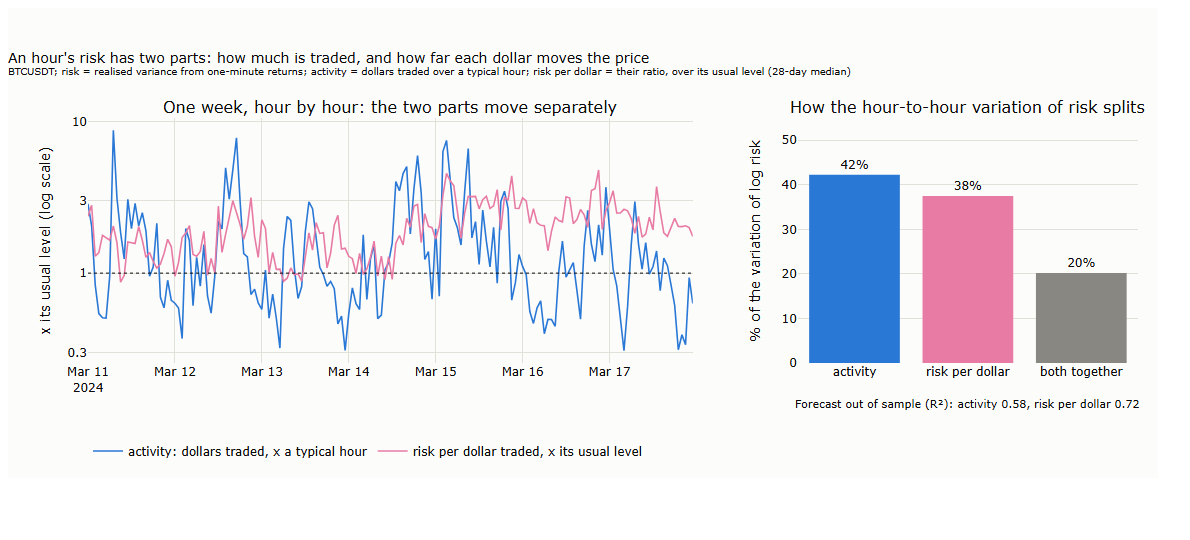

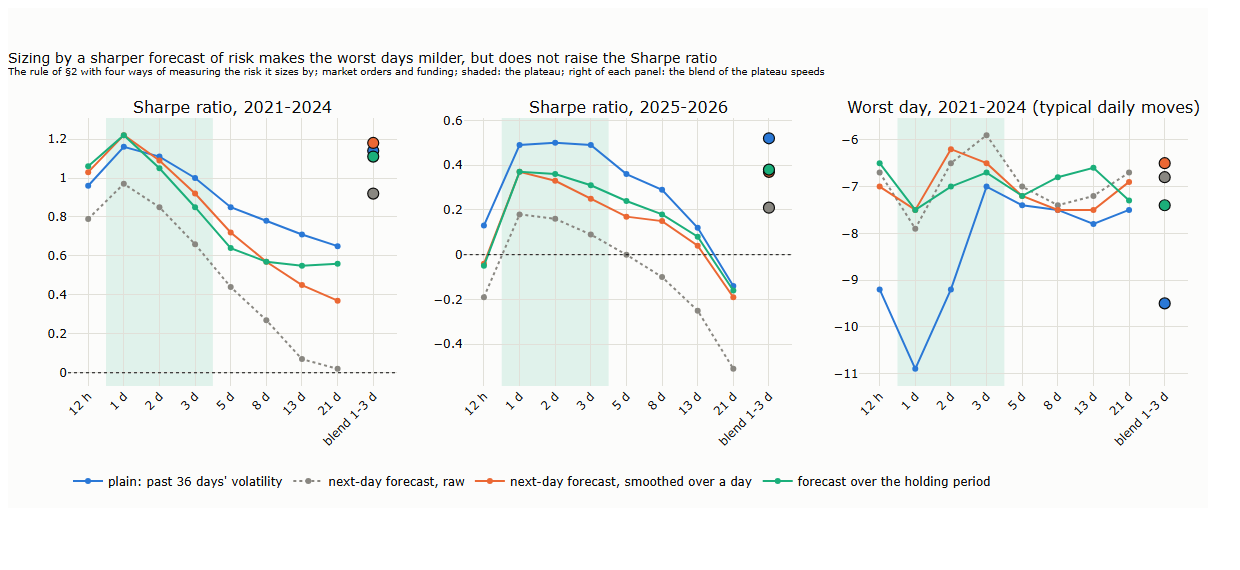

**Decomposition of the variance of log risk:** {'var_log_rv': 1.488, 'var_log_activity': 0.629, 'var_log_risk_per_activity': 0.558, 'two_cov': 0.301, 'corr': 0.254}

forecast,2021-2024,2025-2026
str,f64,f64
"""M0 constant""",-0.1,-0.134
"""M1 seasonal""",0.163,0.221
"""M2 last hour""",0.413,0.449
"""M3 HAR""",0.546,0.577
"""M4 HAR + releases""",0.553,0.583


measure,2021-2024,2025-2026
str,f64,f64
"""plain: past 36 days""",0.38,0.3233
"""next-day forecast, raw""",0.2629,0.2301
"""next-day forecast, smoothed""",0.293,0.2535
"""asymmetric: larger of raw and smoothed""",0.2742,0.2401


sizing,Sharpe 2021-2024,Sharpe 2025-2026,worst day,spread of risk,costs
str,f64,f64,f64,f64,f64
"""plain: past 36 days""",1.14,0.52,-9.5,0.58,0.02
"""next-day forecast, raw""",0.92,0.21,-6.8,0.45,0.0578
"""next-day forecast""",1.18,0.37,-6.5,0.46,0.0179
"""holding-period forecast""",1.11,0.38,-7.4,0.48,0.0174


In [5]:
run("l16_activity.py"); run("l16_horizon.py"); run("l16_legs_risk.py"); run("l16_s4_charts.py")
pictures("16_06_two_parts_of_risk", "16_07_sizing")
a = result("l16_activity.json"); lr = result("l16_legs_risk.json")
display(Markdown(f"**Decomposition of the variance of log risk:** {a['decomposition']}"))
display(pl.DataFrame([{"forecast": k, **v} for k, v in a["activity"].items() if isinstance(v, dict) and "2021-2024" in v]))
display(pl.DataFrame([{"measure": k, **v} for k, v in lr["forecast"].items()]))
h = result("l16_horizon.json")["blend 1-2-3 d"]
pl.DataFrame([{"sizing": k, "Sharpe 2021-2024": v["2021-2024"]["sharpe"], "Sharpe 2025-2026": v["2025-2026"]["sharpe"], "worst day": v["2021-2024"]["worst_day"],
               "spread of risk": v["2021-2024"]["vol_cv"], "costs": v["2021-2024"]["cost"]} for k, v in h.items()])

## 5. The execution clock

Lecture §5: the patient entry of Lecture 15 (rest one tick inside, re-post every 5 seconds, market order after a minute) at every speed; figure 16_08.

l16_s5.py: 4 s


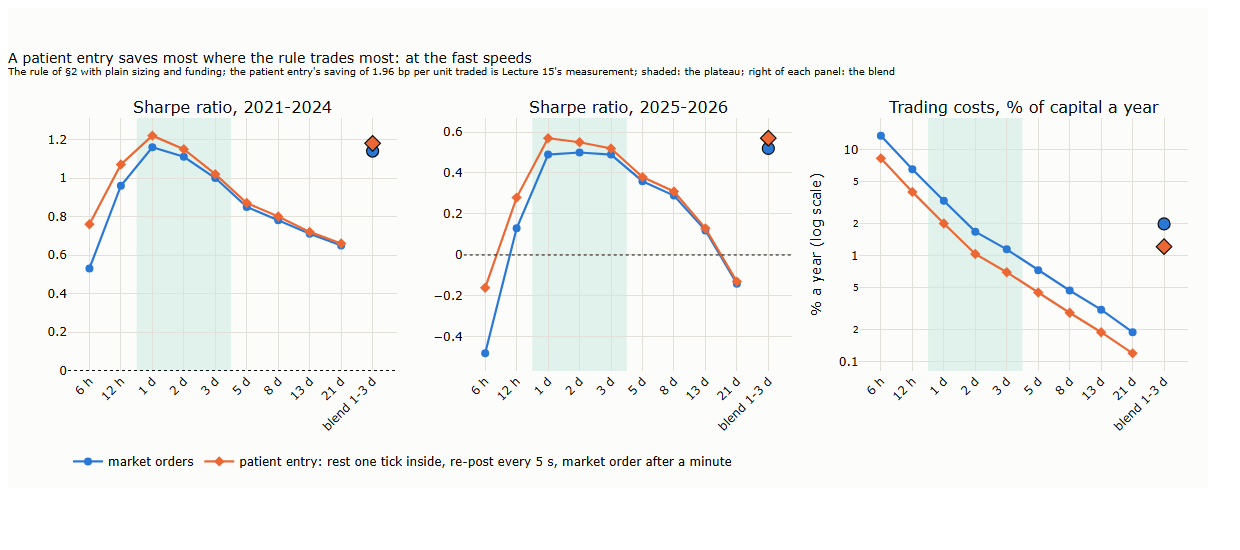

speed,entry,Sharpe 2021-2024,Sharpe 2025-2026,costs
str,str,f64,f64,f64
"""0.25 d""","""market orders""",0.53,-0.48,0.1361
"""0.25 d""","""patient entry""",0.76,-0.16,0.0831
"""0.5 d""","""market orders""",0.96,0.13,0.0656
"""0.5 d""","""patient entry""",1.07,0.28,0.0401
"""1 d""","""market orders""",1.16,0.49,0.0331
"""1 d""","""patient entry""",1.22,0.57,0.0202
"""2 d""","""market orders""",1.11,0.5,0.0169
"""2 d""","""patient entry""",1.15,0.55,0.0104
"""3 d""","""market orders""",1.0,0.49,0.0115


In [6]:
run("l16_s5.py")
pictures("16_08_patient_entry")
s5 = result("l16_s5.json")
pl.DataFrame([{"speed": s, "entry": k, "Sharpe 2021-2024": v["2021-2024"]["sharpe"], "Sharpe 2025-2026": v["2025-2026"]["sharpe"], "costs": v["2021-2024"]["cost"]}
              for s, row in s5.items() for k, v in row.items()])

## 6. Holding

Lecture §6 (figure 16_09 is shown in §1 of the lecture): the premium at each funding snapshot against bitcoin's next 8 and 24 hours and the rule's
legs; the rule's longs held in the perpetual or in spot.

l16_s6.py: 3 s


l16_spot.py: 1 s


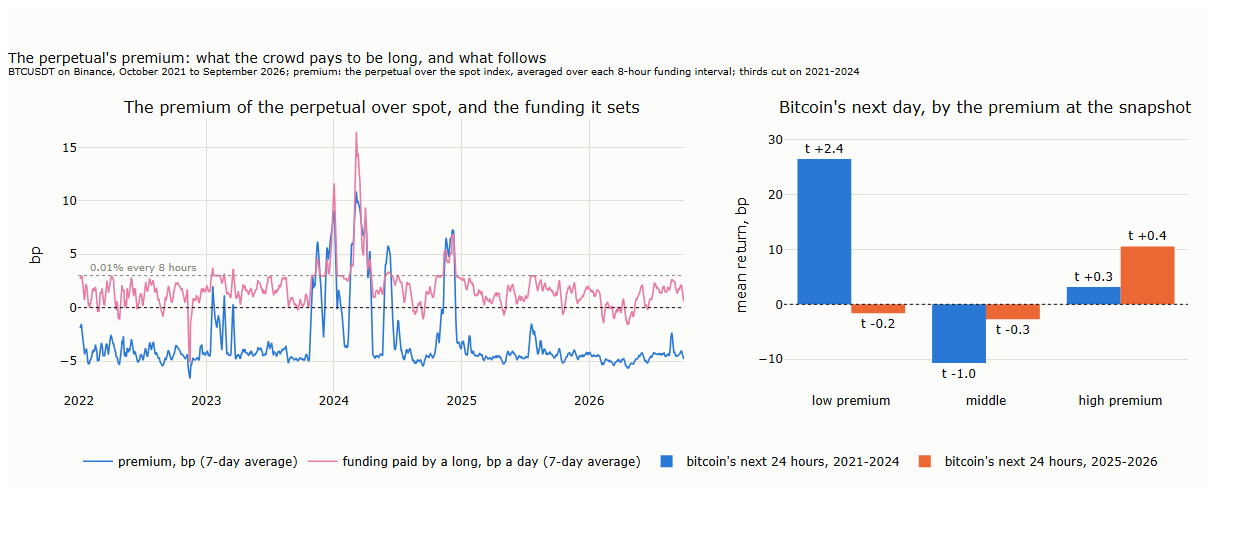

sample,premium third,n,premium_bp,funding_bp,share_long,btc_8h,btc_24h,long_8h,short_8h
str,str,i64,f64,f64,f64,str,str,str,str
"""2021-2024""","""low""",1096,-5.16,0.04,0.36,"""[11.29, 2.2]""","""[26.5, 2.4]""","""[2.31, 2.1]""","""[-1.34, -0.9]"""
"""2021-2024""","""middle""",1095,-3.94,0.71,0.47,"""[-6.6, -1.5]""","""[-10.69, -1.0]""","""[1.08, 1.1]""","""[1.4, 1.5]"""
"""2021-2024""","""high""",1096,2.23,1.44,0.72,"""[1.92, 0.4]""","""[3.18, 0.3]""","""[3.03, 1.7]""","""[0.55, 0.5]"""
"""2025-2026""","""low""",978,-5.04,0.11,0.48,"""[0.27, 0.1]""","""[-1.64, -0.2]""","""[-0.1, -0.2]""","""[0.49, 0.3]"""
"""2025-2026""","""middle""",834,-4.09,0.64,0.49,"""[-2.74, -0.7]""","""[-2.74, -0.3]""","""[1.67, 1.4]""","""[0.31, 0.3]"""
"""2025-2026""","""high""",97,-1.73,0.99,0.82,"""[9.68, 0.7]""","""[10.56, 0.4]""","""[1.18, 0.1]""","""[-1.65, -1.3]"""


longs in,Sharpe 2021-2024,Sharpe 2025-2026,costs,funding,risk-free forgone
str,f64,f64,f64,f64,f64
"""longs in the perpetual""",1.18,0.57,0.0122,0.0141,0.0
"""longs in spot""",1.16,0.49,0.0277,-0.0033,0.0061


In [7]:
run("l16_s6.py"); run("l16_spot.py")
pictures("16_09_premium")
s6 = result("l16_s6.json")
display(pl.DataFrame([{"sample": smp, "premium third": th, **{k: (str(v) if isinstance(v, list) else v) for k, v in row.items()}} for smp, b in s6["by_third"].items() for th, row in b.items()]))
sp = result("l16_spot.json")
pl.DataFrame([{"longs in": k, "Sharpe 2021-2024": v["2021-2024"]["sharpe"], "Sharpe 2025-2026": v["2025-2026"]["sharpe"], "costs": v["2021-2024"]["cost"],
               "funding": v["2021-2024"]["funding"], "risk-free forgone": v["2021-2024"]["carry"]} for k, v in sp.items()])

## 7. The rule built up

Lecture §7: the steps and the two alternatives (figure 16_10), the long and short legs year by year, the equity lines (figure 16_11), and capacity
from the square-root law at the rule's trade size.

l16_legs_year.py: 1 s


l16_s7.py: 1 s


l16_s7_charts.py: 6 s


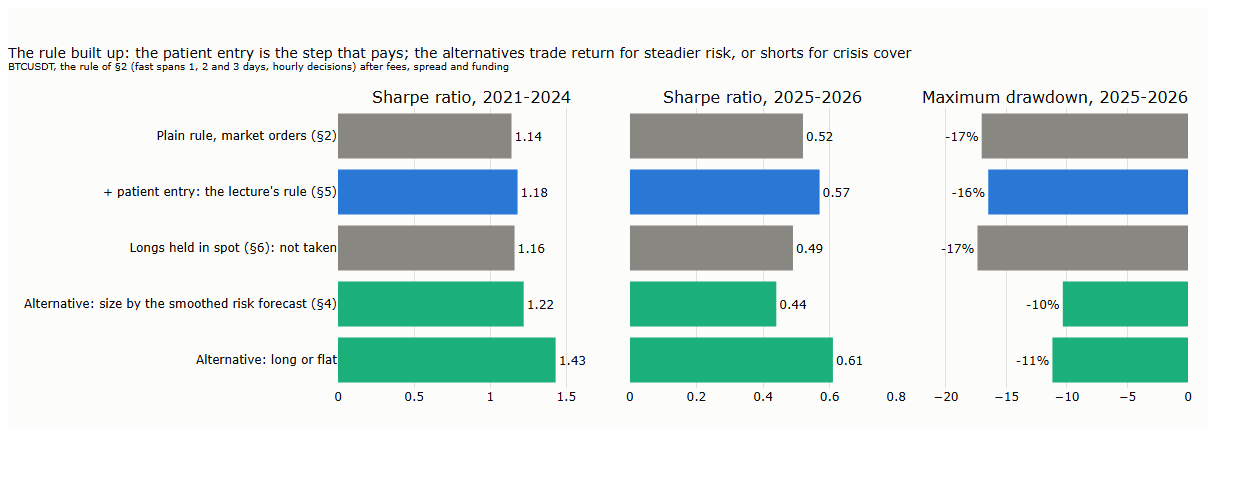

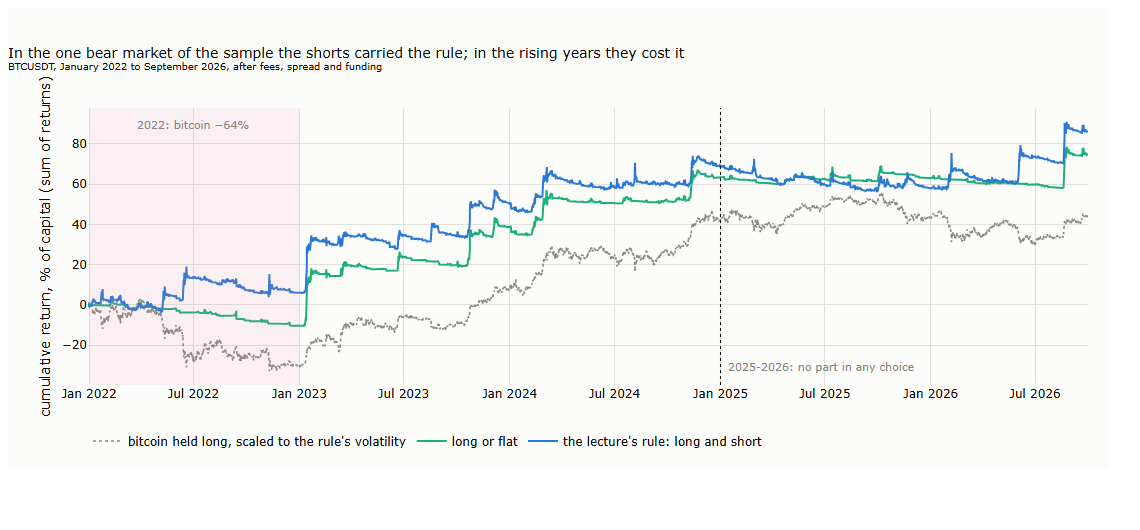

version,Sharpe 2021-2024,Sharpe 2025-2026,max fall 2025-2026,worst day,costs,funding
str,f64,f64,f64,f64,f64,f64
"""0 plain rule, market orders""",1.14,0.52,-0.1704,-9.5,0.02,0.0141
"""1 + patient entry (the lecture's rule)""",1.18,0.57,-0.165,-9.5,0.0122,0.0141
"""1x longs held in spot""",1.16,0.49,-0.1739,-9.5,0.0277,-0.0033
"""alternative: sizing by the smoothed risk forecast""",1.22,0.44,-0.1034,-6.5,0.0109,0.0111
"""alternative: long or flat""",1.43,0.61,-0.112,-8.3,0.0072,0.0174


rule,year,long,short
f64,str,f64,f64
0.064,"""2022""",-0.105,0.169
0.443,"""2023""",0.493,-0.049
0.186,"""2024""",0.243,-0.057
-0.112,"""2025""",-0.004,-0.108
0.282,"""2026""",0.12,0.162
-0.104,"""2022""",-0.104,0.0
0.491,"""2023""",0.491,0.0
0.245,"""2024""",0.245,0.0
-0.003,"""2025""",-0.003,0.0


**Trades:** {'per_year': 1892.0, 'median_size': 0.022, 'mean_size': 0.022, 'turnover_per_year': 41.6, 'gross_per_unit_traded_bp': 64.5, 'mean_abs_position': 0.23}

capital,trade,minutes_of_trading,impact_bp,cost_per_year
f64,f64,f64,str,str
1e7,220000.0,0.02,"""[0.5, 0.9]""","""[0.2, 0.4]"""
1e8,2.2e6,0.24,"""[1.6, 2.9]""","""[0.7, 1.2]"""
1.0000e9,2.2e7,2.44,"""[5.1, 9.3]""","""[2.1, 3.9]"""
5.0000e9,1.1e8,12.18,"""[11.5, 20.7]""","""[4.8, 8.6]"""


In [8]:
run("l16_legs_year.py"); run("l16_s7.py"); run("l16_s7_charts.py")
pictures("16_10_rule_built_up", "16_11_equity")
s7 = result("l16_s7.json")
display(pl.DataFrame([{"version": k, "Sharpe 2021-2024": v["2021-2024"]["sharpe"], "Sharpe 2025-2026": v["2025-2026"]["sharpe"], "max fall 2025-2026": v["2025-2026"]["maxdd"],
                       "worst day": v["2021-2024"]["worst_day"], "costs": v["2021-2024"]["cost"], "funding": v["2021-2024"]["funding"]} for k, v in s7["variants"].items()]))
display(pl.DataFrame([{"rule": k, "year": y, **r} for k, rows in s7["by_year"].items() for y, r in rows.items()]))
display(Markdown(f"**Trades:** {s7['trades']}"))
pl.DataFrame([{k: (str(v) if isinstance(v, (list, tuple)) else v) for k, v in r.items()} for r in result("l16_capacity.json")])

## 8. The grid

Lecture §8: the classic two-sided paired grid, a schematic (figure 16_12).

l16_s8_chart.py: 3 s


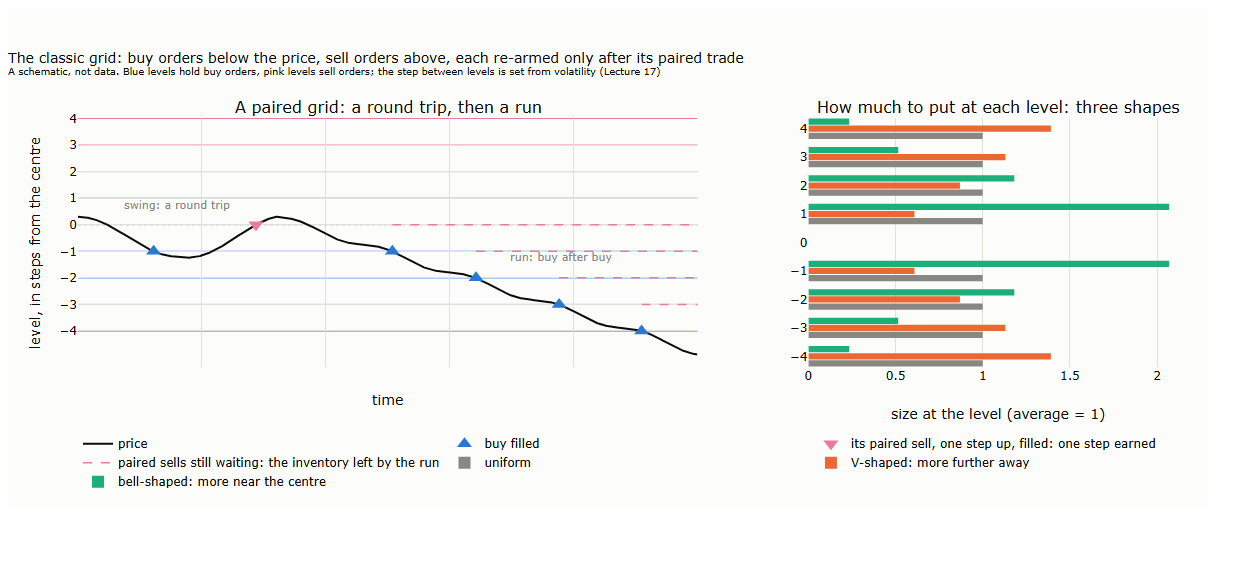

In [9]:
run("l16_s8_chart.py")
pictures("16_12_grid")

## 9. A test of your own

The plain rule of §2 on another market whose one-minute bars Lecture 12's pipeline has built, for example SOLUSDT or ETHUSDT (exercise 1 of §9.2):
hourly closes, fast spans from half a day to two weeks, slow span four times the fast, market orders at 5 bp. Funding is left out here: add it
from that market's funding history to complete the comparison.

In [10]:
SYMBOL = "BTCUSDT"                 # change to a market you have built with Lecture 12's notebook
d = tape.ROOT / "interim" / "tape" / SYMBOL
h = (pl.scan_parquet(sorted(d.glob("*/m1.parquet"))).select("time", "close").collect().sort("time")
     .group_by_dynamic("time", every="1h").agg(pl.col("close").last()).drop_nulls())
p = h["close"].to_numpy(); r = np.r_[0.0, p[1:] / p[:-1] - 1]; n = len(p)
sig = np.sqrt(pl.Series(r ** 2).ewm_mean(span=36 * 24, min_samples=7 * 24).to_numpy() * 24 * 365)
sd = pl.Series(np.r_[0.0, np.diff(p)] ** 2).ewm_mean(span=36 * 24, min_samples=7 * 24).sqrt().to_numpy()
rows = []
for fd in (0.5, 1, 2, 3, 5, 8, 14):
    f = fd * 24; raw = (pl.Series(p).ewm_mean(span=f, adjust=False).to_numpy() - pl.Series(p).ewm_mean(span=4 * f, adjust=False).to_numpy()) / sd
    ok = np.isfinite(raw); fc = raw / (np.cumsum(np.where(ok, np.abs(raw), 0)) / np.maximum(np.cumsum(ok), 1))
    pos = np.nan_to_num(fc * 0.10 / sig); pos[: 90 * 24] = 0
    net = np.r_[0.0, pos[:-1]] * r - np.abs(np.diff(np.r_[0.0, pos])) * 5e-4
    m = np.arange(n) >= 90 * 24
    rows.append(dict(fast_span_days=fd, sharpe=round(float(net[m].mean() / net[m].std() * np.sqrt(24 * 365)), 2), costs_per_year=round(float((np.abs(np.diff(np.r_[0.0, pos])) * 5e-4)[m].sum() / (m.sum() / 8760)), 4)))
pl.DataFrame(rows)

fast_span_days,sharpe,costs_per_year
f64,f64,f64
0.5,0.66,0.0748
1.0,0.93,0.0376
2.0,0.93,0.0189
3.0,0.83,0.0127
5.0,0.72,0.008
8.0,0.66,0.0055
14.0,0.54,0.0038


Where is the plateau of speeds on your market, and does it lie as fast as on bitcoin? Compare with figure 16_03.